In [1]:
!pip install numpy pandas matplotlib tensorflow


Defaulting to user installation because normal site-packages is not writeable


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from tensorflow.keras.datasets import mnist

(x_train, y_train),(x_test,y_test) = mnist.load_data()

In [4]:
x_train.shape

(60000, 28, 28)

In [5]:
x_test.shape

(10000, 28, 28)

In [ ]:
single_image =x_train[0]

In [40]:
single_image

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170, 253, 253, 253, 253, 253, 225, 172

In [15]:
single_image.shape


(28, 28)

In [16]:
single_image.max()


np.uint8(255)

In [17]:
single_image.min()

np.uint8(0)

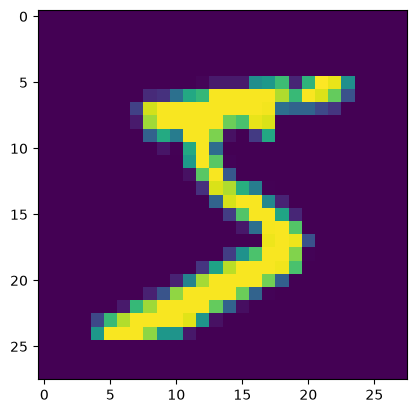

In [18]:
plt.imshow(single_image)

In [28]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

In [29]:
y_train.shape

(60000,)

In [30]:
y_test

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8)

In [31]:
y_test.shape    

(10000,)

In [34]:
from tensorflow.keras.utils import to_categorical

In [35]:
y_cat_train = to_categorical(y_train)

In [36]:
y_cat_train[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

In [37]:
y_cat_train.shape

(60000, 10)

In [43]:
y_cat_test= to_categorical(y_test)

In [44]:
y_cat_test[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

In [45]:
y_cat_test.shape

(10000, 10)

In [46]:
#Normalise the date to 0-1 values
x_train = x_train/255
y_train = y_train/255

In [48]:
x_train[0].max()

np.float64(1.0)

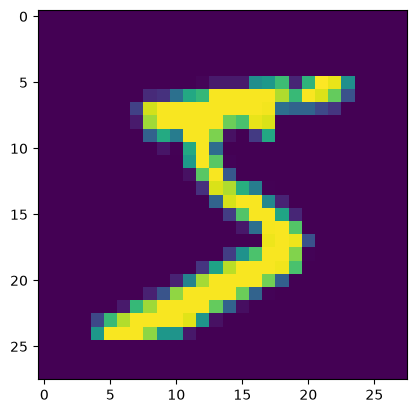

In [49]:
plt.imshow(x_train[0])

In [ ]:
x_train = x_train.reshape(60000,28,28,1) #1 bcs grayscale, 3 is for colored

In [52]:
x_train.shape

(60000, 28, 28, 1)

In [55]:
x_test = x_test.reshape(10000,28,28,1)

In [56]:
x_test.shape

(10000, 28, 28, 1)

## CNN Model

In [57]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten

In [59]:
model = Sequential()

model.add(Conv2D(filters=32, kernel_size=(4,4), input_shape=(28,28,1), activation= 'relu'))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128, activation = 'relu'))
model.add(Dense(10, activation = 'softmax'))

c:\Users\naree\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [60]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 25, 25, 32)     │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,786 (2.26 MB)

 Trainable params: 591,786 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

In [78]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor = 'val_loss', patience = 2)

In [79]:
model.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [91]:
model.fit(x_train, y_cat_train, epochs=10, validation_split=0.1, callbacks=[early_stop])

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9971 - loss: 0.0081 - val_accuracy: 0.9977 - val_loss: 0.0064
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9983 - loss: 0.0057 - val_accuracy: 0.9948 - val_loss: 0.0161
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9980 - loss: 0.0059 - val_accuracy: 0.9953 - val_loss: 0.0127


In [92]:
model.metrics_names

['loss', 'compile_metrics']

In [93]:
losses = pd.DataFrame(model.history.history)

In [94]:
losses

,accuracy,loss,val_accuracy,val_loss
0,0.997093,0.008129,0.997667,0.006440
1,0.998315,0.005662,0.994833,0.016088
2,0.998019,0.005914,0.995333,0.012727


<Axes: >

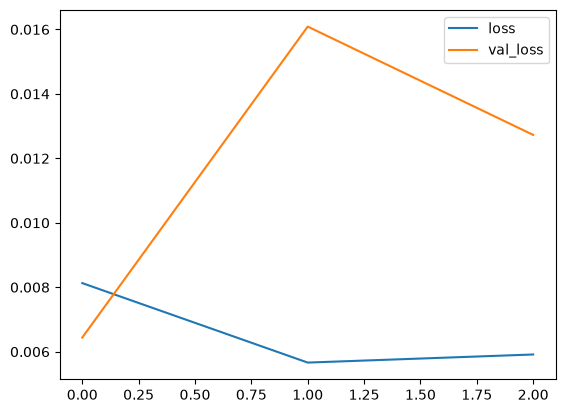

In [95]:
losses[['loss','val_loss']].plot()

<Axes: >

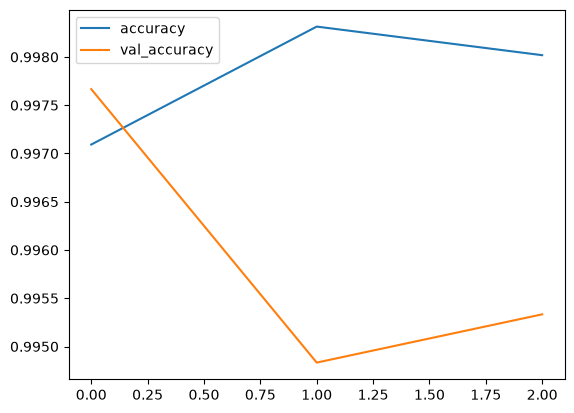

In [96]:
losses[['accuracy','val_accuracy']].plot()

In [97]:
model.save('digit_recognition_model.keras')